# Comparing stocks

One page across every stock run with `python run.py`, built from the summaries each report saved in `reports/summaries/`. It has the same two parts as the reports:

- **Part 1, direction:** up or down tomorrow, judged against "always up."
- **Part 2, move size:** big or small move tomorrow, judged against the "Recent swing" rule (with "same as today" for context).

**The lucky-winners problem.** Test enough stocks and models, and some will "win" by chance alone. At the usual 5% level, about 1 comparison in 20 passes even when nothing real is going on. So each part shows two bars:

- **5%:** the usual threshold for a single test.
- **Corrected:** the *Holm correction*. Sort the p-values from smallest to largest: the smallest must clear 5% divided by the number of comparisons, the next 5% divided by one fewer, and so on, stopping at the first that misses. A result has to clear this to count as evidence once many things were tested. The two parts answer different questions, so each is corrected on its own.

Every accuracy is compared with its baseline using a **paired test**: a baseline predicts the same days as the model, so only the days where they disagree count. The 95% ranges in the charts come from the same days.

In [1]:
# Settings (run.py replaces these)
TICKERS = ["SPY"]

In [2]:
# Parameters
TICKERS = ["SPY", "NVDA", "AAPL", "GOOGL"]


In [3]:
import sys
from pathlib import Path

# Find the project folder, whether this runs from the project, notebooks/ or reports/
ROOT = Path.cwd()
if ROOT.name in ("notebooks", "reports"):
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from IPython.display import Markdown, display

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
# Same colors in every report: blue, orange, aqua, yellow
plt.rcParams["axes.prop_cycle"] = cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])

import numpy as np
from src.report import comparison_table, load_summaries

summaries = load_summaries(TICKERS)
dir_table, dir_info = comparison_table(summaries, task="direction")
vol_table, vol_info = comparison_table(summaries, task="volatility")
print(f"Stocks: {', '.join(TICKERS)}")

MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def plot_edges(table, edge_column, baseline, title):
    """Each model's accuracy minus the baseline's, with the 95% range of that difference."""
    plot = table.reset_index()
    models = list(dict.fromkeys(plot["model"]))
    stocks = list(dict.fromkeys(plot["stock"]))
    colors = dict(zip(models, MODEL_COLORS))
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(stocks) * len(models) + 1.5))
    y, ticks, labels = 0, [], []
    for stock in stocks:
        for model in models:
            row = plot[(plot["stock"] == stock) & (plot["model"] == model)].iloc[0]
            ax.errorbar(row[edge_column] * 100, y, xerr=row[f"{edge_column} ±"] * 100, fmt="o", color=colors[model],
                        markersize=8, capsize=4, linewidth=2, label=model if stock == stocks[0] else None)
            ticks.append(y)
            labels.append(f"{stock}  {model}")
            y += 1
        y += 0.5
    ax.axvline(0, color="grey", linewidth=1)
    ax.set_yticks(ticks, labels)
    ax.invert_yaxis()
    ax.set_xlabel(f'accuracy minus "{baseline}" (percentage points)')
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=len(models), frameon=False)
    plt.tight_layout()
    plt.show()


def luck_summary(info, accuracy_test, luck_test):
    """How many passes there are, next to how many luck alone would produce."""
    n, n_luck = info["comparisons"], info["luck comparisons"]
    models_per_stock = n // max(len(TICKERS), 1)
    display(Markdown(f"""
{len(TICKERS)} stocks × {models_per_stock} models.

| Test | Comparisons | Passes expected by luck at 5% | Strictest corrected bar (Holm) | Passes at 5% | Passes after correction |
|---|---|---|---|---|---|
| {accuracy_test} | {n} | about {info["expected chance passes"]:.1f} | p-value at most {info["corrected threshold"]:.4f} | {info["accuracy passes (5%)"]} of {n} | {info["accuracy passes (corrected)"]} of {n} |
| {luck_test} | {n_luck} | about {info["expected chance luck passes"]:.1f} | luck share at most {info["luck corrected threshold"]:.4f} | {info["luck passes (5%)"]} of {n_luck} | {info["luck passes (corrected)"]} of {n_luck} |
"""))

Stocks: SPY, NVDA, AAPL, GOOGL


# Part 1: direction

## 1. Test periods

Each stock is tested from its own first test year, so periods can differ for stocks with shorter histories.

In [4]:
pd.DataFrame([
    {"stock": s["ticker"], "test start": s["test start"], "test end": s["test end"],
     "test days": s["test days"], "always up accuracy": s["always up accuracy"],
     "buy and hold annual return": s["buy and hold"]["annual return"]}
    for s in summaries
]).set_index("stock")

,test start,test end,test days,always up accuracy,buy and hold annual return
stock,,,,,
SPY,2010-01-04,2026-10-14,4221,0.5520,0.1412
NVDA,2010-01-04,2026-10-14,4221,0.5283,0.4515
AAPL,2010-01-04,2026-10-14,4221,0.5309,0.2680
GOOGL,2010-01-04,2026-10-14,4221,0.5285,0.2041


## 2. Accuracy against "always up"

**Edge** is the model's accuracy minus the "always up" accuracy for the same stock and days. Zero means no better than always predicting up. The bars show the 95% range of that difference, from the paired counts: if a bar crosses zero, the edge could be luck.

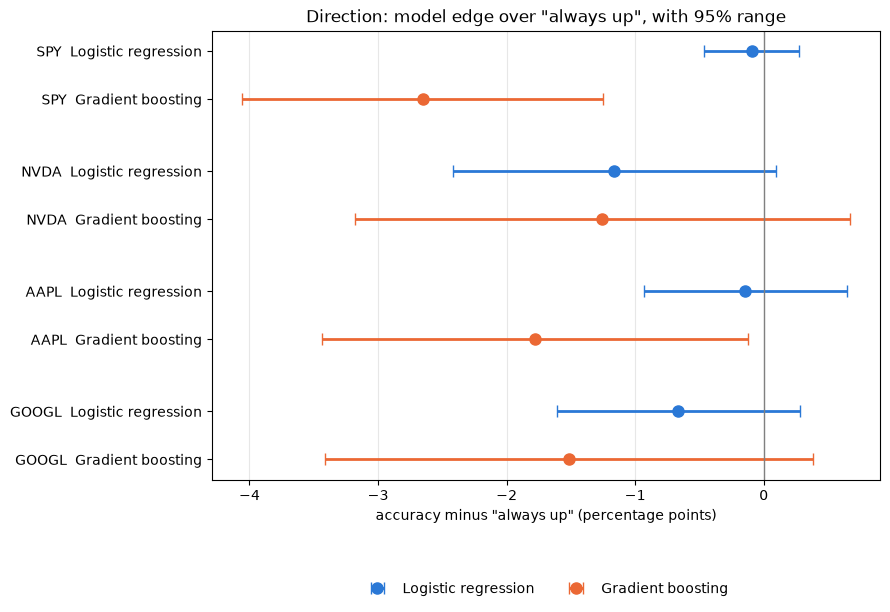

In [5]:
plot_edges(dir_table, "edge", "always up", 'Direction: model edge over "always up", with 95% range')

## 3. Full table

- **edge ±:** half the width of the edge's 95% range.
- **p-value vs always up:** the paired test: the chance of being right on this many of the days the model said "down", if it were no better than "always up."
- **share of random >=:** from the luck check: how often random cash days did at least as well in the backtest, on annual return. Empty when a model never left the market.
- The four True/False columns: does the result pass at 5%, and does it pass the corrected bar?

In [6]:
dir_table

accuracy  always up    edge  edge ±  \
stock model                                                      
SPY   Logistic regression    0.5511     0.5520 -0.0009  0.0037   
      Gradient boosting      0.5255     0.5520 -0.0265  0.0140   
NVDA  Logistic regression    0.5167     0.5283 -0.0116  0.0126   
      Gradient boosting      0.5158     0.5283 -0.0126  0.0192   
AAPL  Logistic regression    0.5295     0.5309 -0.0014  0.0079   
      Gradient boosting      0.5131     0.5309 -0.0178  0.0166   
GOOGL Logistic regression    0.5219     0.5285 -0.0066  0.0095   
      Gradient boosting      0.5134     0.5285 -0.0152  0.0190   

                           p-value vs always up  annual return  buy and hold  \
stock model                                                                    
SPY   Logistic regression                0.7338         0.1488        0.1412   
      Gradient boosting                  0.9999         0.0522        0.1412   
NVDA  Logistic regression                0.9676         0.3462        0.4515   
      Gradient boosting                  0.9038         0.2675        0.4515   
AAPL  Logistic regression                0.6600         0.2256        0.2680   
      Gradient boosting                  0.9834         0.0976        0.2680   
GOOGL Logistic regression                0.9225         0.1239        0.2041   
      Gradient boosting                  0.9442         0.0409        0.2041   

                           share of random >=  accuracy edge (5%)?  \
stock model                                                          
SPY   Logistic regression              0.0475                False   
      Gradient boosting                0.9995                False   
NVDA  Logistic regression              0.6202                False   
      Gradient boosting                0.4293                False   
AAPL  Logistic regression              0.8501                False   
      Gradient boosting                0.9935                False   
GOOGL Logistic regression              0.9955                False   
      Gradient boosting                0.9875                False   

                           accuracy edge (corrected)?  beats luck (5%)?  \
stock model                                                               
SPY   Logistic regression                       False              True   
      Gradient boosting                         False             False   
NVDA  Logistic regression                       False             False   
      Gradient boosting                         False             False   
AAPL  Logistic regression                       False             False   
      Gradient boosting                         False             False   
GOOGL Logistic regression                       False             False   
      Gradient boosting                         False             False   

                           beats luck (corrected)?  
stock model                                         
SPY   Logistic regression                    False  
      Gradient boosting                      False  
NVDA  Logistic regression                    False  
      Gradient boosting                      False  
AAPL  Logistic regression                    False  
      Gradient boosting                      False  
GOOGL Logistic regression                    False  
      Gradient boosting                      False

## 4. How many wins would luck produce?

In [7]:
luck_summary(dir_info, 'Accuracy beats "always up"', "Backtest beats luck (annual return)")
display(Markdown("A handful of passes at 5%, close to what luck predicts, is **not** evidence of skill. "
                 "Only results that also pass the corrected bar, and that hold up on future data "
                 "(phase 6, the live forward test), deserve attention."))


4 stocks × 2 models.

| Test | Comparisons | Passes expected by luck at 5% | Strictest corrected bar (Holm) | Passes at 5% | Passes after correction |
|---|---|---|---|---|---|
| Accuracy beats "always up" | 8 | about 0.4 | p-value at most 0.0063 | 0 of 8 | 0 of 8 |
| Backtest beats luck (annual return) | 8 | about 0.4 | luck share at most 0.0063 | 1 of 8 | 0 of 8 |


A handful of passes at 5%, close to what luck predicts, is **not** evidence of skill. Only results that also pass the corrected bar, and that hold up on future data (phase 6, the live forward test), deserve attention.

# Part 2: move size

## 5. Baselines and buy-and-hold for each stock

- **share of big days:** how often tomorrow's move beat the stock's typical day over the past year.
- **majority:** accuracy of always predicting whichever is more common.
- **same as today:** accuracy of predicting tomorrow will be big if today's move was bigger than usual.
- **recent swing:** accuracy of predicting a big day when today's high-to-low swing was wider than usual for the past year. This is the bar for Part 2.
- **buy and hold:** the Sharpe ratio and worst drop that the half-on-big strategy tries to improve on, next to the Recent swing rule's own weekly half-on-big strategy.

In [8]:
pd.DataFrame([
    {"stock": s["ticker"], "test start": s["volatility"]["test start"], "test days": s["volatility"]["test days"],
     "share of big days": s["volatility"]["share of big days"],
     "majority": s["volatility"]["majority accuracy"],
     "same as today": s["volatility"]["same as today accuracy"],
     "recent swing": s["volatility"]["recent swing accuracy"],
     "buy and hold Sharpe": s["volatility"]["buy and hold"]["Sharpe ratio"],
     "buy and hold max drawdown": s["volatility"]["buy and hold"]["max drawdown"],
     "recent swing weekly Sharpe": s["volatility"]["recent swing strategy"]["strategy (weekly)"]["Sharpe ratio"]}
    for s in summaries
]).set_index("stock")

,test start,test days,share of big days,majority,same as today,recent swing,buy and hold Sharpe,buy and hold max drawdown,recent swing weekly Sharpe
stock,,,,,,,,,
SPY,2010-01-04,4221,0.4923,0.5077,0.5330,0.6162,0.7743,-0.3372,0.6727
NVDA,2010-01-04,4221,0.4973,0.5027,0.5165,0.5508,1.0144,-0.6634,1.0332
AAPL,2010-01-04,4221,0.4954,0.5046,0.5302,0.5648,0.9338,-0.4380,0.8105
GOOGL,2010-01-04,4221,0.4999,0.5001,0.5058,0.5473,0.7527,-0.4432,0.5704


## 6. Accuracy against the rules

**Edge** is the model's accuracy minus the rule's accuracy for the same stock and days. The bars show the 95% range of that difference. Model and rule agree on most days, and those days add no uncertainty, so the ranges are narrow; they match the paired test in the table below.

First against "same as today", the bar from phase 4, then against Recent swing, the tougher bar:

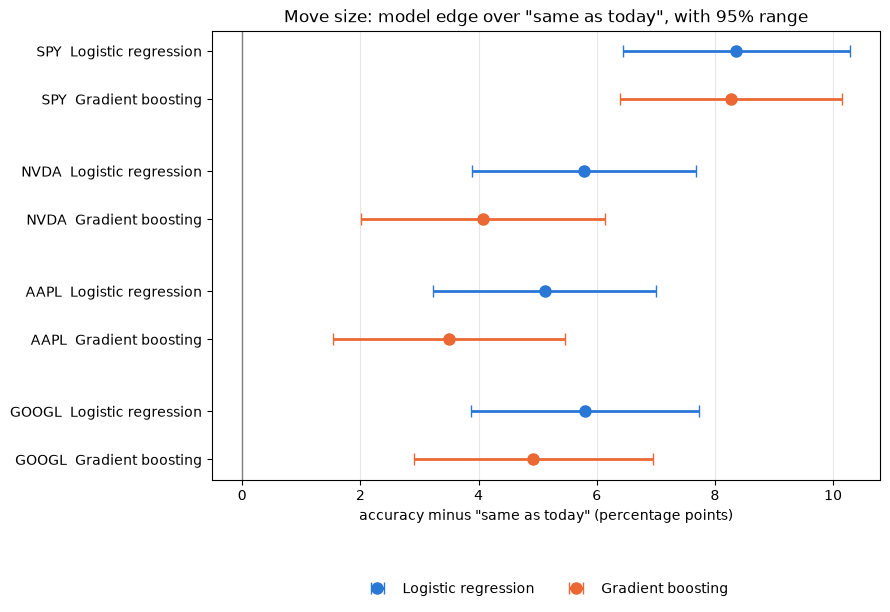

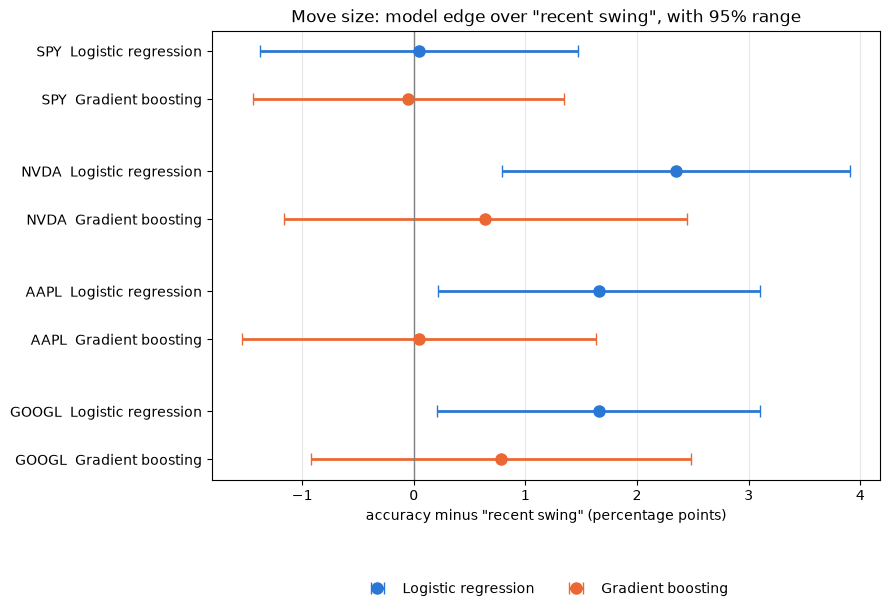

In [9]:
plot_edges(vol_table, "edge over same as today", "same as today",
           'Move size: model edge over "same as today", with 95% range')
plot_edges(vol_table, "edge", "recent swing", 'Move size: model edge over "recent swing", with 95% range')

## 7. Full table

- **edge / p-value vs recent swing:** the main test. The p-value is the paired test: the chance of winning this many of the days where model and rule disagree, if the model were no better.
- **edge / p-value vs same as today:** the same for the weaker rule, for context. **beats same as today (corrected)?** uses the same corrected bar.
- **Sharpe (daily / weekly):** the half-on-big strategy (full position on predicted calm days, half on predicted big days), deciding every day or once a week, after trading costs, next to buy-and-hold. The worst drop is shown for the weekly version.
- **share of random >= (daily / weekly):** from the luck checks: how often random half-position days, or random whole weeks, reached at least the same Sharpe ratio.
- **beats luck, daily / weekly:** each strategy is a separate comparison, so the corrected luck bar divides 5% by twice the number of rows.

In [10]:
vol_table

accuracy  recent swing  same as today    edge  \
stock model                                                                
SPY   Logistic regression    0.6167        0.6162         0.5330  0.0005   
      Gradient boosting      0.6157        0.6162         0.5330 -0.0005   
NVDA  Logistic regression    0.5743        0.5508         0.5165  0.0235   
      Gradient boosting      0.5572        0.5508         0.5165  0.0064   
AAPL  Logistic regression    0.5814        0.5648         0.5302  0.0166   
      Gradient boosting      0.5653        0.5648         0.5302  0.0005   
GOOGL Logistic regression    0.5638        0.5473         0.5058  0.0166   
      Gradient boosting      0.5551        0.5473         0.5058  0.0078   

                           edge ±  p-value vs recent swing  \
stock model                                                  
SPY   Logistic regression  0.0142                   0.4870   
      Gradient boosting    0.0140                   0.5397   
NVDA  Logistic regression  0.0156                   0.0018   
      Gradient boosting    0.0180                   0.2518   
AAPL  Logistic regression  0.0144                   0.0131   
      Gradient boosting    0.0158                   0.4883   
GOOGL Logistic regression  0.0145                   0.0134   
      Gradient boosting    0.0170                   0.1909   

                           edge over same as today  edge over same as today ±  \
stock model                                                                     
SPY   Logistic regression                   0.0836                     0.0192   
      Gradient boosting                     0.0827                     0.0188   
NVDA  Logistic regression                   0.0578                     0.0190   
      Gradient boosting                     0.0407                     0.0207   
AAPL  Logistic regression                   0.0512                     0.0189   
      Gradient boosting                     0.0351                     0.0196   
GOOGL Logistic regression                   0.0580                     0.0193   
      Gradient boosting                     0.0493                     0.0203   

                           p-value vs same as today  Sharpe (daily)  ...  \
stock model                                                          ...   
SPY   Logistic regression                    0.0000          0.6130  ...   
      Gradient boosting                      0.0000          0.4981  ...   
NVDA  Logistic regression                    0.0000          0.9669  ...   
      Gradient boosting                      0.0001          0.8553  ...   
AAPL  Logistic regression                    0.0000          0.9612  ...   
      Gradient boosting                      0.0003          0.7681  ...   
GOOGL Logistic regression                    0.0000          0.6496  ...   
      Gradient boosting                      0.0000          0.6094  ...   

                           max drawdown (buy and hold)  \
stock model                                              
SPY   Logistic regression                      -0.3372   
      Gradient boosting                        -0.3372   
NVDA  Logistic regression                      -0.6634   
      Gradient boosting                        -0.6634   
AAPL  Logistic regression                      -0.4380   
      Gradient boosting                        -0.4380   
GOOGL Logistic regression                      -0.4432   
      Gradient boosting                        -0.4432   

                           share of random >= (daily)  \
stock model                                             
SPY   Logistic regression                      0.9760   
      Gradient boosting                        1.0000   
NVDA  Logistic regression                      0.5207   
      Gradient boosting                        0.9310   
AAPL  Logistic regression                      0.1629   
      Gradient boosting                        0.9405   
GOOGL Logistic regression           

## 8. How many wins would luck produce?

In [11]:
luck_summary(vol_info, 'Accuracy beats "recent swing"', "Half-on-big, daily or weekly, beats luck (Sharpe ratio)")
display(Markdown(f'For context, against the weaker "same as today" rule: '
                 f'{vol_info["same as today passes (corrected)"]} of {vol_info["comparisons"]} pass after correction.'))


4 stocks × 2 models.

| Test | Comparisons | Passes expected by luck at 5% | Strictest corrected bar (Holm) | Passes at 5% | Passes after correction |
|---|---|---|---|---|---|
| Accuracy beats "recent swing" | 8 | about 0.4 | p-value at most 0.0063 | 3 of 8 | 1 of 8 |
| Half-on-big, daily or weekly, beats luck (Sharpe ratio) | 16 | about 0.8 | luck share at most 0.0031 | 0 of 16 | 0 of 16 |


For context, against the weaker "same as today" rule: 8 of 8 pass after correction.

## 9. Conclusions

*Write this in your own words.* Some prompts:

- **Direction:** did any stock show a real edge after the correction? Were results consistent across stocks?
- **Move size:** did the models beat "same as today" on every stock after the correction? And the Recent swing rule? What does that say about where the predictability comes from?
- Did predicting move size improve the Sharpe ratio or the worst drop, after trading costs? Did deciding weekly change the answer?
- How much did buy-and-hold differ between stocks, and how much of that is hindsight from picking well-known winners?